# C2 evaluation - diffusion counterfactuals

The same figures as `C2_evaluation.ipynb`, read off the **generated** counterfactual arm.
Nothing is retrained here; this reads the fold predictions written by
`c2_train_attributes.py` / `c2_train_images.py`.

**What differs from the KNN notebook**

| | `C2_evaluation.ipynb` | this notebook |
|---|---|---|
| counterfactual | nearest correctly-classified train image | FastDiME trajectory from the query itself |
| `SOURCE` | `knn_correct_cf` | `diffusion_hml_sub20k` |
| rows | the whole C2 table (~80-92k) | the frozen 20,000-image subset |
| **K means** | how many *neighbours* are retrieved | how many *intensity levels* are used |

That last row is the one to keep in mind. K is not a neighbourhood size here: the three
counterfactuals of a query are the same edit at three strengths, ordered `high, mid, low`, so
K=1 is the strongest edit alone and K=3 adds the two weaker ones. Slot 0 is `high` at both K,
which is what makes K=1 a strict prefix of K=3.

**Sections 1b and 1d are the comparison against the KNN arm** - the figure this whole
experiment exists to produce. Both arms are built on the same 20,000 rows, the same
patient-grouped folds and the same seed, so the counterfactual source is the only thing that
differs. Each of those figures has two rows: the two arms on an absolute AUROC axis, and
directly beneath, their difference with a sign.

The difference row is the one to read. The arms sit within a few thousandths of each other on
most configs, which at the absolute scale is two lines on top of one another.

Every comparison panel checks `same_rows` first and refuses to draw if the two arms do not
cover the identical images. Run `c2_compare_arms.py` for the stronger version of that check -
it verifies the fold assignment too, not just the row set.

**No bootstrap yet.** The lollipops carry no confidence intervals and the ensemble panels
carry no significance brackets - the differences are drawn as point estimates only. Read them
as "how big is the gap", not "is the gap real".

The two aims, and the sections, are unchanged.

**Aim 1 - is there correctness signal in counterfactuals?** Every attribute config (1a) and
every CNN variant (1c) on an absolute AUROC scale, as itself rather than as a difference, then
each of those against the KNN arm (1b, 1d).

**Aim 2 - is it better than the baseline?** The single best attribute config and best CNN per
disease, against MSP, then the two combined.

**The baseline is MSP**, straight off C0 with nothing fitted on top, in the
`MSP_VARIANT = "threshold"` form: the probability of the class C0 actually predicted at
its Youden threshold. C0 does not predict at 0.5, so plain `max(p, 1-p)` measures distance
from a decision it never makes. This matches `C2_evaluation.ipynb` -- it has to, or the two
notebooks draw different reference lines and their Aim 2 gaps cannot be compared. It is drawn
as a thin grey dashed reference everywhere and is never a series colour. `B1.2` is excluded:
binary entropy is a monotone transform of `max(p, 1-p)`, so it ranks identically and *is* the
baseline drawn twice.

## Setup

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import roc_auc_score

sys.path.insert(0, os.path.abspath("code"))
from c2_msp import MSP_VARIANTS, msp_score

# Which MSP baseline every figure is drawn against. MUST match C2_evaluation.ipynb,
# or the two notebooks draw different reference lines and their Aim 2 gaps are not
# comparable -- "threshold" is worth +0.02-0.045 AUROC over plain max(p, 1-p), which
# is larger than most of the effects being measured.
MSP_VARIANT = "threshold"

# K = number of INTENSITY LEVELS the counterfactual features are pooled over, not a
# neighbourhood size. The levels are ordered high, mid, low, so K=1 is the strongest
# edit alone and K=3 adds the two weaker ones.
CF       = 1
K_VALUES = [1, 3]
K_LEVELS = {1: "high", 3: "high+mid+low"}

RESULTS = os.environ.get("THESIS_RESULTS", "/work3/s251710/thesis_results")
C2      = os.path.join(RESULTS, "C2_final_results")

# The arm. SOURCE is the only directory component that distinguishes it from the KNN
# arm, so changing this line is the whole difference between the two notebooks.
SOURCE, POLICY = "diffusion_hml_sub20k", "ignore"

# The comparator. Same 20,000 rows, same folds, same seed -- the ONLY difference is
# where the counterfactual came from. That is what makes the paired figures below a
# statement about counterfactuals rather than about two unrelated experiments, and
# `same_rows` checks it rather than assuming it.
KNN_SOURCE = "knn_correct_cf_sub20k"

SUBSET   = "20k"
DISEASES = ["atelectasis", "cardiomegaly", "consolidation"]

CNN_KEYS   = ["xi", "xi_sal", "cf", "cf_sal", "dual", "dual_sal", "dual_sal_scalars"]
CNN_GROUPS = [["xi", "xi_sal", "cf", "cf_sal"], ["dual", "dual_sal", "dual_sal_scalars"]]
# The image models that never see a counterfactual. Shaded in the CNN ladder, and the
# reason their K lines coincide: with no CF input there is nothing for K to vary.
CNN_NO_CF  = ["xi", "xi_sal"]

# Canonical config order -- NOT sorted by performance, so a config sits at the same x
# in every panel and the eye can track it across diseases. B1.2 is excluded (see above).
CONFIG_GROUPS = [
    ["B1", "B2", "B3", "B4", "B5"],
    ["M1", "M2", "M3", "M4", "M5", "M6"],
    ["MCF1", "MCF2", "MCF3", "MCF4", "MCF5"],
]
CONFIG_ORDER = [c for g in CONFIG_GROUPS for c in g]

# Thesis-wide style: colour = model family, lightness = how much counterfactual a model
# sees, figures drawn at print size. See code/thesis_style.py.
import importlib, thesis_style
importlib.reload(thesis_style)     # pick up edits to the style file without a kernel restart
from thesis_style import *
apply()

# This notebook's arm IS the trajectory family, which is exactly what FAMILY["traj"]
# was reserved for -- so the diffusion series are orange here and in every figure that
# ever puts the two arms together, while the KNN arm keeps the attribute blue it has
# in C2_evaluation.ipynb. The two notebooks therefore never disagree about what a
# colour means.
BLUE, TEAL, TRAJ = FAMILY["attr"], FAMILY["cnn"], FAMILY["traj"]
K_COLOR   = k_colors("traj", K_VALUES)
ARMS      = {"diffusion": SOURCE, "KNN": KNN_SOURCE}
ARM_COLOR  = {"diffusion": FAMILY["traj"], "KNN": FAMILY["attr"]}
# Shape as well as hue: the two arms overlap almost everywhere, and a reader who
# cannot separate the hues still separates circles from squares.
ARM_MARKER = {"diffusion": "o", "KNN": "s"}

print(f"arm: {SOURCE}  ({FAMILY_LABEL['traj']})   MSP: {MSP_VARIANT}")
print(f"diseases: {', '.join(DISEASES)}")

arm: diffusion_hml_sub20k  (trajectory)   MSP: threshold
diseases: atelectasis, cardiomegaly, consolidation


## Loaders

In [2]:
# Every loader takes `source`, defaulting to this notebook's arm. That one argument is
# what lets the comparison figures read the KNN arm with the identical code path -- a
# second set of loaders is how the two arms would quietly stop being read the same way.
def attr_dir(d, k=None, source=None):
    return os.path.join(C2, d, source or SOURCE, f"cf_{k or CF}", "attributes")

def cnn_dir(d, key, k=None, source=None):
    return os.path.join(C2, d, source or SOURCE, f"cf_{k or CF}", "images", key)

def load_attributes(disease, k=None, n_folds=5, source=None):
    """Pooled out-of-fold attribute predictions for one K; `fold` kept so per-fold means
    stay available. Returns None if that K has not finished, so a partially run sweep
    still renders -- which matters here, where K=3 needs the mid and low levels to have
    been materialised."""
    parts = []
    for i in range(n_folds):
        p = os.path.join(attr_dir(disease, k, source), f"fold_{i}_predictions.csv")
        if not os.path.exists(p):
            return None
        f = pd.read_csv(p); f["fold"] = i
        parts.append(f)
    return pd.concat(parts, ignore_index=True)

def load_cnn(disease, k=None, n_folds=5, source=None):
    """Pooled OOF CNN predictions, one column per FINISHED model (fold_aucs.csv present),
    so the notebook works mid-run.

    Columns are renamed `cnn_<key>`: the `cf` model writes `cf_prob`, which collides with
    the attribute frame's own `cf_prob` (mean counterfactual C0 probability) on merge.
    """
    out = None
    for key in CNN_KEYS:
        if not os.path.exists(os.path.join(cnn_dir(disease, key, k, source), "fold_aucs.csv")):
            continue
        parts = []
        for i in range(n_folds):
            p = os.path.join(cnn_dir(disease, key, k, source), f"fold_{i}_predictions.csv")
            if not os.path.exists(p): break
            f = pd.read_csv(p); f["fold"] = i
            parts.append(f)
        else:
            df = (pd.concat(parts, ignore_index=True)
                    [["path", "patient_id", "correct", "fold", f"{key}_prob"]]
                    .rename(columns={f"{key}_prob": f"cnn_{key}"}))
            out = df if out is None else out.merge(df[["path", f"cnn_{key}"]],
                                                   on="path", how="outer")
    return out

def msp(df, disease, variant=None):
    """Maximum softmax probability -- the untrained baseline. Nothing is fitted.
    `variant` defaults to MSP_VARIANT; the threshold is only read when a variant needs it."""
    variant = variant or MSP_VARIANT
    p = df[f"{disease}_prob"].values
    t = None if variant == "standard" else c0_threshold(disease)
    return msp_score(p, t, variant)

def config_cols(df, model="MLP"):
    """Config -> column, in CONFIG_ORDER. Configs absent from the file are skipped."""
    have = {c.split("_", 1)[1].rsplit("_prob", 1)[0]: c
            for c in df.columns if c.startswith(f"{model}_") and c.endswith("_prob")}
    return {c: have[c] for c in CONFIG_ORDER if c in have}

def c0_threshold(disease, policy=POLICY):
    p = os.path.join(RESULTS, "C0_final", f"multilabel_{policy}", disease, "threshold.txt")
    return float(open(p).read().strip())

def per_fold_auc(df, score_col_or_values):
    """Mean AUROC over the 5 folds -- the same statistic cv_summary.csv reports."""
    v = df[score_col_or_values] if isinstance(score_col_or_values, str) else pd.Series(
        score_col_or_values, index=df.index)
    return float(np.mean([roc_auc_score(g["correct"], v.loc[g.index])
                          for _, g in df.groupby("fold")]))

def panel_note(df, disease, policy=POLICY):
    """Per-panel subtitle: sample count and C0's error profile.

    n is ~20,000 on every disease here, not the full table: this arm is restricted to
    the frozen subset the counterfactuals were generated for. It is still not identical
    across diseases, because rows with an uncertain (-1) CheXpert label have no defined
    correctness and are dropped before the subset is taken.

    FP/FN split C0's errors by the class it predicted. Neither `pred` nor `true` is stored
    in the fold predictions, but both are recoverable: pred = prob >= threshold, and since
    `correct` is exactly (pred == true), a wrong row has true = 1 - pred.
    """
    corr = df["correct"].values.astype(int)
    pred = (df[f"{disease}_prob"].values >= c0_threshold(disease, policy)).astype(int)
    n  = len(df)
    fp = ((pred == 1) & (corr == 0)).sum() / n
    fn = ((pred == 0) & (corr == 0)).sum() / n
    return f"n={n:,}  ·  C0 err {1 - corr.mean():.1%}  (FP {fp:.1%} / FN {fn:.1%})"

def available():
    """What has finished, per disease and K. Run this first -- the arm is built
    incrementally and an empty figure is otherwise indistinguishable from a bad path."""
    rows = []
    for d in DISEASES:
        for k in K_VALUES:
            a = load_attributes(d, k)
            c = load_cnn(d, k)
            rows.append({"disease": d, "K": k,
                         "attributes": "-" if a is None else f"{len(a):,} rows",
                         "CNN models": "-" if c is None else
                                       sum(c[f"cnn_{x}"].notna().all()
                                           for x in CNN_KEYS if f"cnn_{x}" in c.columns)})
    return pd.DataFrame(rows)

available()

,disease,K,attributes,CNN models
0,atelectasis,1,"20,000 rows",7
1,atelectasis,3,"20,000 rows",7
2,cardiomegaly,1,"20,000 rows",7
3,cardiomegaly,3,"20,000 rows",7
4,consolidation,1,"20,000 rows",7
5,consolidation,3,-,-


# Aim 1 - is there correctness signal in counterfactuals?

Nothing in this section is a comparison against the baseline; that is Aim 2. Each config is
plotted at **its own AUROC**, so the reading is "how well does this set of inputs rank C0's
errors" rather than "how much does it add". The shape of the line across configs is the thing:
it says which inputs carry the signal, and in particular what the counterfactual features
(`MCF*`) buy over the query-only ones (`M*`).

**One line per K** - here, per number of intensity levels. K=1 is the `high` counterfactual
alone; K=3 pools `high`, `mid` and `low`. Asking whether K helps is asking whether the weaker
edits carry information the strong one does not. A K that has not finished is simply absent
from the panel.

MSP is drawn as a thin grey dashed horizontal line - a reference, not a series.

**Each panel gets its own y range**, computed from that panel's own configs, because the
differences that matter are thousandths of AUROC and one range wide enough for three diseases
flattens them. The absolute level is in each panel title.

The y range is **windowed**: `B2` and `M1` sit far below everything else and would crush the
competitive band on their own. They are clipped at the panel floor with their value listed
under the panel.

Configs run along x in the canonical `B* -> M* -> MCF*` order rather than by rank, so a config
sits at the same x in every panel; hairlines separate the three families.

### Plot helpers

In [3]:
def line_panel(ax, rows, series, groups, ylim, base=None, colors=None, shade=None,
               markers=None, note_offset=None):
    """One disease: AUROC against config, one line per K.

    `note_offset` is how far below the axes the clipped-values note goes, in POINTS.
    It defaults to just under the rotated tick labels; the stacked comparison figure
    overrides it, because a second panel sits directly below and the default would
    print the note behind it.

    Values below the windowed floor are CLIPPED to it and listed under the panel, not
    dropped: the line has to stay connected or the eye reads a gap as a missing config,
    but drawing the true value would undo the window. The clipped marker is hollow so it
    cannot be misread as a real position.
    """
    lo, hi  = ylim
    colors  = colors or K_COLOR
    markers = markers or k_markers(series)
    x       = np.arange(len(rows))
    ax.set_ylim(lo, hi)

    # Shade the reference family rather than only ruling a line after it: a band says
    # "this region is different in kind" where a rule only says "something changes here".
    # `shade` is an explicit config list, not a group index -- in the CNN ladder the
    # models with no counterfactual input are a PREFIX of the first group, so shading
    # group 0 would wrongly cover cf and cf_sal.
    if shade:
        idx = [i for i, c in enumerate(rows) if c in shade]
        if idx:
            ax.axvspan(min(idx) - 0.5, max(idx) + 0.5, color=SHADE, lw=0, zorder=0)

    if base is not None:
        msp_line(ax, base)

    seen = 0
    for g in groups[:-1]:
        seen += sum(1 for c in g if c in rows)
        if 0 < seen < len(rows):
            ax.axvline(seen - 0.5, color=HAIR, lw=LW["axis"], zorder=0)

    clipped = {}
    for k, vals in series.items():
        y    = np.array([vals.get(c, np.nan) for c in rows], float)
        clip = y < lo
        ax.plot(x, np.where(clip, lo, y), "-", marker=markers[k], ms=3.5, lw=LW["line"],
                mec="white", mew=0.5, color=colors[k], zorder=3, label=f"K={k}")
        for xi, yi in zip(x[clip], y[clip]):
            ax.plot(xi, lo, "o", ms=4.5, mfc="white", mec=colors[k], mew=1.0, zorder=4)
            clipped.setdefault(int(xi), []).append(yi)

    # Clipped configs are listed in ONE note under the axes rather than labelled in place,
    # where several of them land on top of each other and on the lines.
    if clipped:
        names = ", ".join(rows[i] for i in sorted(clipped))
        worst = min(v for vs in clipped.values() for v in vs)
        drop = (note_offset if note_offset is not None
                else 0.75 * FS["tiny"] * max(len(r) for r in rows) + 9)
        ax.annotate(f"below axis: {names}  (min {worst:.3f})", xy=(0, 0),
                    xycoords="axes fraction", xytext=(0, -drop), textcoords="offset points",
                    fontsize=FS["tiny"], color=MUTED, va="top", ha="left")

    # Rows are the GLOBAL config list, identical in every panel, so a config keeps its x
    # position across diseases and a missing one leaves a gap rather than shifting the rest.
    ax.set_xticks(x); ax.set_xticklabels(rows, rotation=90, fontsize=FS["tiny"])
    ax.set_xlim(-0.5, len(rows) - 0.5)
    ax.yaxis.set_major_locator(plt.MaxNLocator(5))
    # Square PLOTTING AREA. set_box_aspect fixes the axes box, where a square figsize would
    # only fix the cell and let the labels squash the plot inside it. Not set_aspect("equal"),
    # which equalises data units -- x spans 16 config slots against y's ~0.05 AUROC.
    ax.set_box_aspect(1)
    ax.grid(axis="y", zorder=0); ax.set_axisbelow(True)
    return ax


def k_legend(ks, colors=None, shade_label="no counterfactual input"):
    colors  = colors or K_COLOR
    markers = k_markers(ks)
    return ([line_handle(colors[k], f"K={k} ({K_LEVELS[k]})", markers[k]) for k in ks]
            + [Line2D([], [], color=MUTED, lw=0, marker="o", ms=4.5, mfc="white", mew=1.0,
                      label="clipped to axis floor (listed under panel)"),
               patch_handle(SHADE, shade_label),
               msp_handle("MSP baseline")])


def _grid(n, ncols, panel=(FULL / 3, 76 * MM)):
    """Axes grid with the unused trailing cells removed. Cells are taller than wide even
    though the axes are square: the extra height is what the rotated x labels, the two
    title lines and the below-axis note consume."""
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel[0] * ncols, panel[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.remove()
    return fig, axes[:n]


def auroc_ylim(series, base, win=0.05):
    """Y window for one panel: a fixed-height `win` band anchored at the TOP of the data.

    Anchored at the top, not fitted to the full range, because the configs that matter sit
    within a few thousandths of each other near the ceiling. Anything below is clipped and
    listed by `line_panel`. MSP is always inside the window -- it is the line every config
    is read against -- so the window is widened to reach it rather than re-centred.
    """
    vals = [v for d in series.values() for v in d.values() if np.isfinite(v)]
    if base is not None and np.isfinite(base):
        vals = vals + [base]
    if not vals:
        return (0.5, 0.5 + win)
    hi  = max(vals)
    lo  = min(hi - win, min(vals) if base is None else min(base, hi - win))
    pad = 0.04 * (hi - lo)
    return (lo - pad, hi + pad)


def _panel_title(ax, disease, df, base=None):
    """Panel title: disease, then a small subtitle with n, C0's error profile and MSP."""
    ax.set_title(disease, pad=11)
    note = panel_note(df, disease)
    if base is not None and np.isfinite(base):
        note += f"  ·  MSP {base:.3f}"
    ax.text(0.0, 1.02, note, transform=ax.transAxes,
            ha="left", va="bottom", fontsize=FS["tiny"], color=MUTED)


# ══════════════════════════════════════════════════════════════════════════════
# ARM COMPARISON
# ══════════════════════════════════════════════════════════════════════════════

def same_rows(a, b):
    """Do two arms' prediction frames cover exactly the same images?

    This is the assumption the whole comparison rests on and it is NOT self-evident:
    the two arms are separate runs against separate fold caches, and a stale cache, a
    re-frozen subset or a half-finished run all produce complete, plausible-looking
    results on different rows. An AUROC difference would then be partly a difference
    in which images were scored, and nothing in the figure would show it.
    """
    return len(a) == len(b) and set(a["path"]) == set(b["path"])


def arm_series(disease, keys, kind="attr", k=None, model="MLP"):
    """{arm: {key: AUROC}} for one disease, plus the reference frame and MSP.

    Returns (series, ref, base, note). `note` is non-empty when something is off --
    a missing arm, or the two arms not covering the same rows -- and the caller
    prints it on the panel rather than silently drawing an unsound comparison.
    """
    series, ref, base, frames = {}, None, None, {}
    for arm, src in ARMS.items():
        att = load_attributes(disease, k, source=src)
        if att is None:
            continue
        if kind == "attr":
            f, cols = att, config_cols(att, model)
            vals = {c: per_fold_auc(f, col) for c, col in cols.items() if c in keys}
        else:
            cnn = load_cnn(disease, k, source=src)
            if cnn is None:
                continue
            # MSP must be scored on the SAME rows as the CNN, so merge and keep one frame.
            f = cnn.merge(att[["path", f"{disease}_prob"]], on="path", how="inner")
            vals = {key: per_fold_auc(f, f"cnn_{key}") for key in keys
                    if f"cnn_{key}" in f.columns and f[f"cnn_{key}"].notna().all()}
        if not vals:
            continue
        series[arm], frames[arm] = vals, f
        if ref is None:
            ref, base = f, per_fold_auc(f, msp(f, disease))

    note = ""
    if len(series) < len(ARMS):
        note = f"only {', '.join(series) or 'no arm'} finished"
    elif not same_rows(*frames.values()):
        note = "ARMS COVER DIFFERENT ROWS - not comparable"
    return series, ref, base, note


# How tall the difference row is, as a fraction of its own width. It is a bar chart read
# for sign and relative size, so it needs far less height than the square ladder above it.
DELTA_ASPECT = 0.62


def arm_compare(keys, kind="attr", groups=None, shade=None, diseases=DISEASES,
                k=None, model="MLP", win=0.05, title="", panel=(FULL / 3, 70 * MM)):
    """Two rows per figure: absolute AUROC for both arms, then their difference.

    The top row is the Aim 1 ladder with the ARM as the series dimension instead of K,
    so it is read exactly like the figures above it -- same order, same shading, same
    MSP reference. It answers "how good is each arm".

    The bottom row is the thing the experiment is actually about: diffusion minus KNN,
    per config, on a zero line. It exists because the top row cannot answer it. The two
    arms sit within a few thousandths of each other on most configs, which at the top
    row's scale is two lines on top of each other; the difference row magnifies exactly
    that and gives it a sign. Bars are coloured by which arm wins, so direction is
    readable without consulting the axis.

    The difference row shares ONE y scale across diseases, unlike the top row: a gap of
    +0.01 has to mean the same length in every panel or the figure invites a comparison
    it does not support.
    """
    panels = []
    for d in diseases:
        series, ref, base, note = arm_series(d, keys, kind, k, model)
        if series:
            panels.append((d, ref, base, series, note))
    if not panels:
        print(f"neither arm has finished {kind} results yet"); return

    rows = [c for c in keys if any(c in s[a] for _, _, _, s, _ in panels for a in s)]

    # Shared difference scale, from the actual differences rather than a guess.
    diffs = {}
    for d, _, _, series, _ in panels:
        if len(series) == len(ARMS):
            diffs[d] = {c: series["diffusion"][c] - series["KNN"][c] for c in rows
                        if c in series["diffusion"] and c in series["KNN"]}
    allv = [v for dd in diffs.values() for v in dd.values()]
    # Floored at 0.001: two arms can agree to the last decimal (they do exactly, when
    # both point at the same run), and a zero-height axis is degenerate. The floor also
    # stops the scale from magnifying pure noise into a dramatic-looking bar.
    dlim = max(max(abs(v) for v in allv) * 1.25, 0.001) if allv else 0.01

    n = len(panels)
    # The two rows share one x axis, so they must share a width; the delta row is drawn
    # DELTA_ASPECT as tall as it is wide, and height_ratios matches so tight_layout has
    # no slack left to stretch either row into.
    fig, axes = plt.subplots(2, n, figsize=(panel[0] * n, panel[1] * (1 + DELTA_ASPECT)),
                             gridspec_kw={"height_ratios": [1.0, DELTA_ASPECT]})
    axes = np.atleast_2d(axes).reshape(2, n)

    for j, (d, ref, base, series, note) in enumerate(panels):
        line_panel(axes[0, j], rows, series, groups or [rows],
                   auroc_ylim(series, base, win), base=base,
                   colors=ARM_COLOR, shade=shade, markers=ARM_MARKER,
                   # No x tick labels on this row, so the note only has to clear the
                   # spine and the tick marks -- but it must clear them, not sit on them.
                   note_offset=11)
        _panel_title(axes[0, j], d, ref, base)
        axes[0, j].set_ylabel("AUROC" if j == 0 else "")
        # The difference panel sits directly below with the same configs on x, so the
        # labels are drawn once, under the pair.
        axes[0, j].set_xticklabels([])
        # Square, like the single-arm ladder panel. Without an explicit aspect the axes
        # stretches to fill the row's share of the figure height and the ladder distorts.
        axes[0, j].set_box_aspect(1)
        if note:
            axes[0, j].text(0.5, 0.02, note, transform=axes[0, j].transAxes,
                            ha="center", va="bottom", fontsize=FS["small"],
                            color=INK if "DIFFERENT" in note else MUTED,
                            fontweight="bold" if "DIFFERENT" in note else "normal")

        ax = axes[1, j]
        dd = diffs.get(d, {})
        x  = np.arange(len(rows))
        ax.axhline(0.0, color=GREY, ls="--", lw=LW["ref"], zorder=2)
        for xi, c in zip(x, rows):
            v = dd.get(c)
            if v is None:
                continue
            ax.bar(xi, v, width=0.68, zorder=3,
                   color=ARM_COLOR["diffusion"] if v >= 0 else ARM_COLOR["KNN"])
        ax.set_ylim(-dlim, dlim)
        ax.set_xticks(x); ax.set_xticklabels(rows, rotation=90, fontsize=FS["tiny"])
        ax.set_xlim(-0.5, len(rows) - 0.5)
        ax.set_ylabel("diffusion − KNN" if j == 0 else "")
        ax.grid(axis="y", zorder=0); ax.set_axisbelow(True)
        ax.set_box_aspect(DELTA_ASPECT)
        if dd:
            w = max(dd, key=lambda c: dd[c])
            drop = 0.75 * FS["tiny"] * max(len(r) for r in rows) + 9
            ax.annotate(f"best for diffusion: {w} ({dd[w]:+.3f})  ·  "
                        f"wins {sum(v > 0 for v in dd.values())}/{len(dd)}",
                        xy=(0, 0), xycoords="axes fraction", xytext=(0, -drop),
                        textcoords="offset points", fontsize=FS["tiny"], color=MUTED,
                        va="top", ha="left")

    handles = ([line_handle(ARM_COLOR[a], a, ARM_MARKER[a]) for a in ARMS]
               + [patch_handle(SHADE, "no counterfactual input (control)"),
                  msp_handle("MSP (top) / no difference (bottom)")])
    fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.03))
    fig.suptitle(title, y=1.0)
    fig.tight_layout(rect=(0, 0.03, 1, 0.99))
    return fig

## 1a. Attribute configs

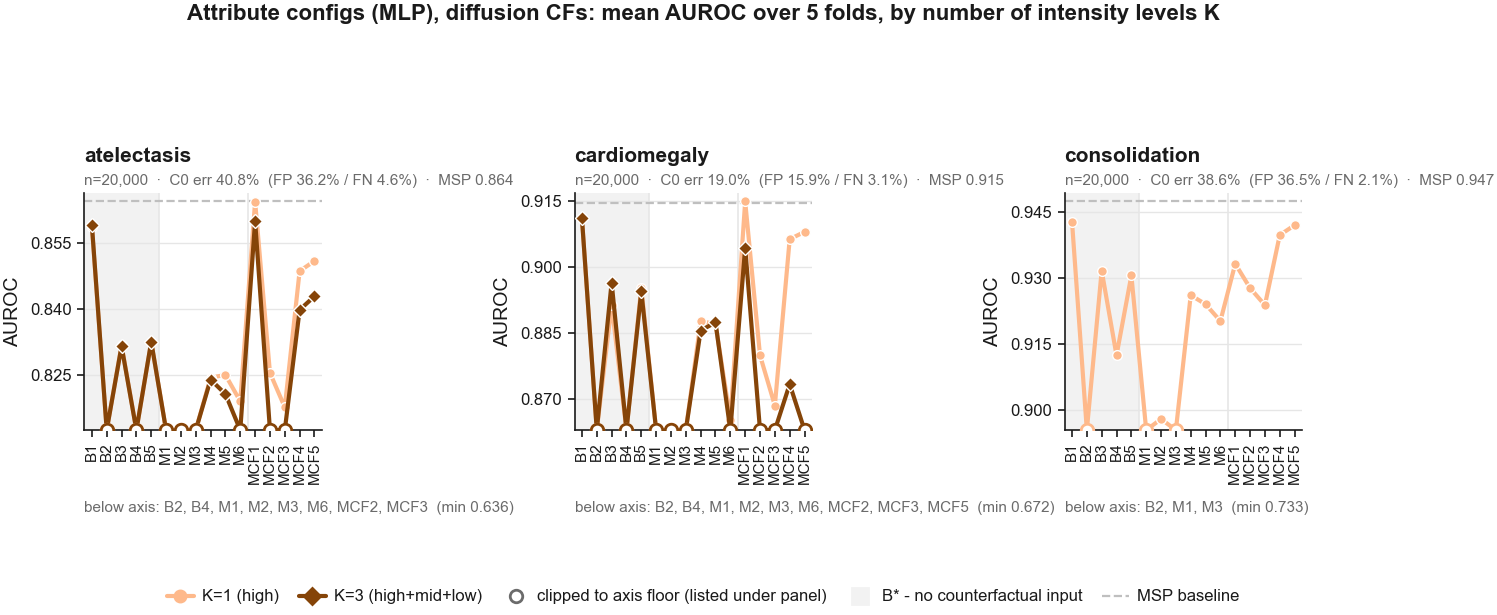

In [4]:
def config_ladder(diseases=DISEASES, model="MLP", ks=None, win=0.05,
                  ncols=3, panel=(FULL / 3, 76 * MM)):
    """AUROC against config, one line per K, one panel per disease."""
    ks, panels = ks or K_VALUES, []
    for d in diseases:
        # {k: frame}; a K that has not finished on this disease is dropped, not faked.
        frames = {k: f for k in ks if (f := load_attributes(d, k)) is not None}
        if not frames:
            continue
        # MSP is K-independent -- same C0 probability on the same rows -- so it is scored
        # once on whichever K is present.
        ref    = frames[next(iter(frames))]
        base   = per_fold_auc(ref, msp(ref, d))
        series = {k: {c: per_fold_auc(f, col) for c, col in config_cols(f, model).items()}
                  for k, f in frames.items()}
        panels.append((d, ref, base, series))

    if not panels:
        print("no attribute predictions yet for", SOURCE); return
    rows = [c for c in CONFIG_ORDER if any(c in s[k] for _, _, _, s in panels for k in s)]

    fig, axes = _grid(len(panels), ncols, panel)
    for ax, (d, ref, base, series) in zip(axes, panels):
        # Shade the B* family: it is the reference the rest of the ladder is read against.
        line_panel(ax, rows, series, CONFIG_GROUPS,
                   auroc_ylim(series, base, win), base=base, shade=CONFIG_GROUPS[0])
        _panel_title(ax, d, ref, base)
        ax.set_ylabel("AUROC")
    drawn = sorted({k for _, _, _, s in panels for k in s})
    fig.legend(handles=k_legend(drawn, shade_label="B* - no counterfactual input"),
               loc="lower center", ncol=len(drawn) + 3, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(f"Attribute configs ({model}), diffusion CFs: mean AUROC over 5 folds, "
                 f"by number of intensity levels K", y=1.0)
    fig.tight_layout(rect=(0, 0.02, 1, 0.99))
    return fig

config_ladder();

## 1b. Attribute configs: diffusion vs KNN

The same ladder with the **arm** as the series instead of K. Both arms are the same 20,000
images, the same patient-grouped folds and the same seed, so the only thing that differs
between the two lines is where the counterfactual came from.

**Read the bottom row, not the top.** The two arms sit within a few thousandths of each other
on most configs, which at the top row's scale is two lines on top of one another. The bottom
row is that difference with a sign: a blue bar is a config where the generated counterfactual
beats the retrieved one, an orange bar the reverse. It shares one y scale across diseases, so
bar lengths are comparable between panels.

**The `B*` configs are the control.** They never see a counterfactual, so the two arms are
running identical models on identical rows and their bars must be ~0. A visible `B*` bar means
the two arms are not on the same footing, and nothing to its right can be trusted. That is
what the shaded band is for here.

`same_rows` is checked before anything is drawn; a panel that fails it says so in red rather
than plotting a comparison that is not one.

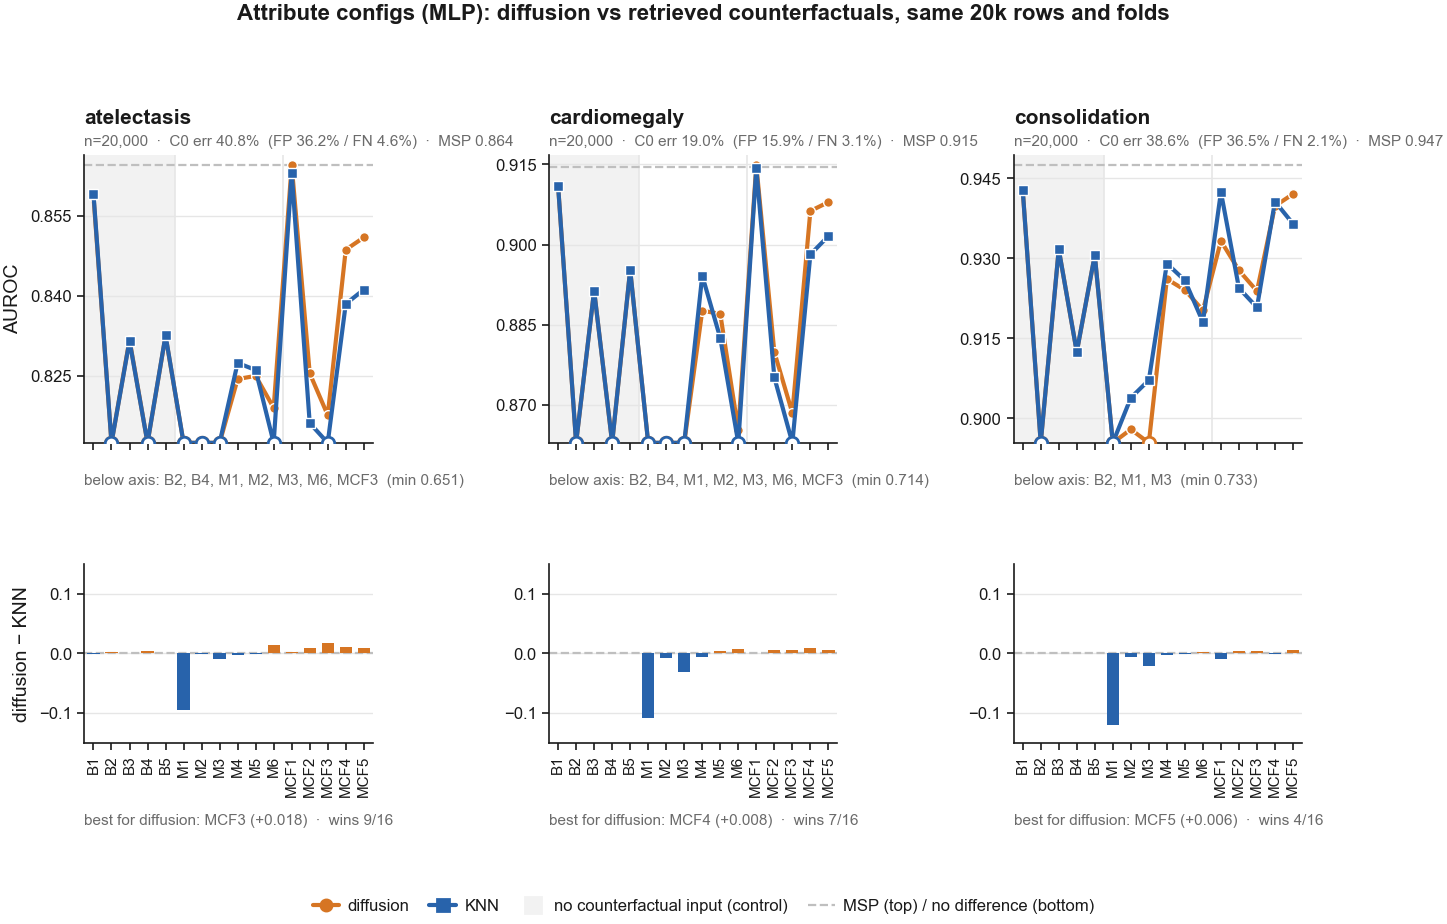

In [5]:
arm_compare(CONFIG_ORDER, kind="attr", groups=CONFIG_GROUPS,
            shade=CONFIG_GROUPS[0],
            title="Attribute configs (MLP): diffusion vs retrieved counterfactuals, "
                  "same 20k rows and folds");

## 1c. CNN variants

The image models on the same absolute axis, read the same way: what does each set of image
inputs know about C0's correctness. The rule separates the models that see a single image from
those that see the query/counterfactual pair, which is the comparison this figure exists to
make.

`xi` and `xi_sal` never open a counterfactual, so their K lines coincide by construction -
that is a check on the pipeline, not a finding. They are the shaded band.

Only models with a complete `fold_aucs.csv` appear, so this renders correctly mid-run.

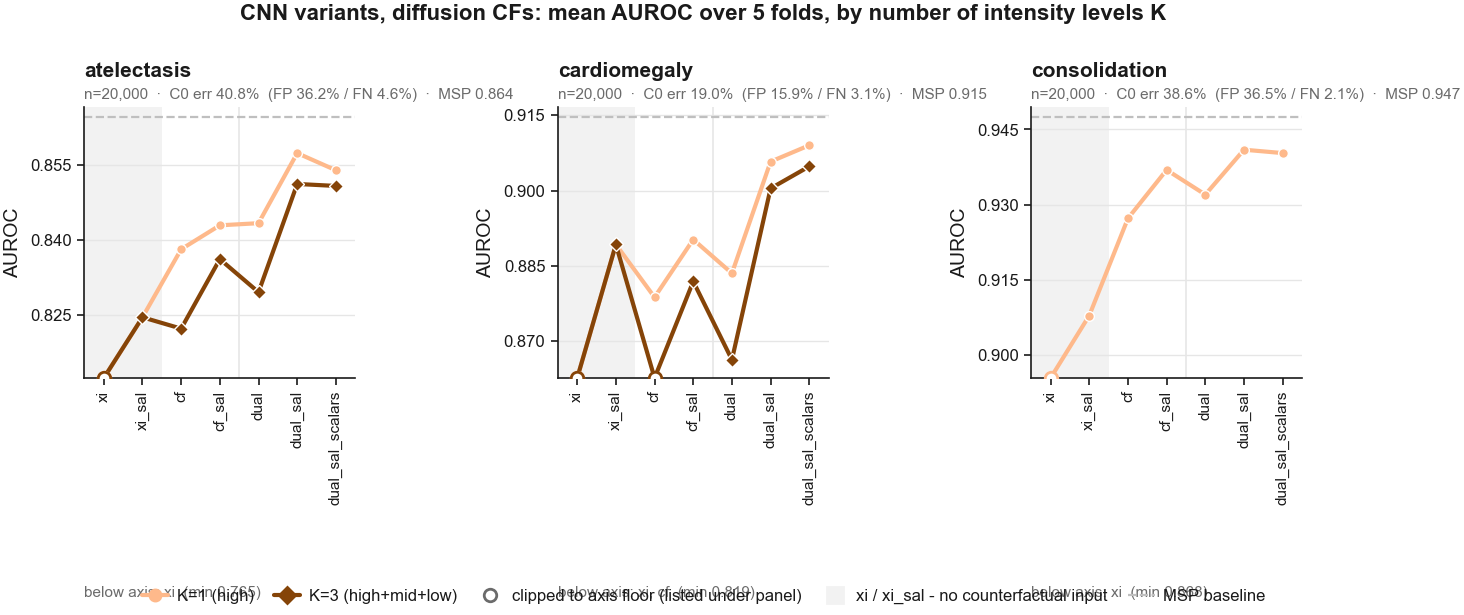

In [6]:
def cnn_ladder(diseases=DISEASES, ks=None, win=0.05, ncols=3, panel=(FULL / 3, 76 * MM)):
    """Same figure for the image models."""
    ks, panels = ks or K_VALUES, []
    for d in diseases:
        # The C0 probability column is what MSP needs and it does not depend on K, so one
        # attribute frame (at CF) supplies it for every K series.
        att = load_attributes(d, CF)
        if att is None: continue
        series, ref, base = {}, None, None
        for k in ks:
            cnn = load_cnn(d, k)
            if cnn is None: continue
            cols = [f"cnn_{key}" for key in CNN_KEYS
                    if f"cnn_{key}" in cnn.columns and cnn[f"cnn_{key}"].notna().all()]
            if not cols: continue
            # MSP must be scored on the SAME rows as the CNN, so merge and take one frame.
            m = cnn.merge(att[["path", f"{d}_prob"]], on="path", how="inner")
            series[k] = {c.replace("cnn_", ""): per_fold_auc(m, c) for c in cols}
            if ref is None:
                ref, base = m, per_fold_auc(m, msp(m, d))
        if series:
            panels.append((d, ref, base, series))

    if not panels:
        print("no finished CNN models yet for", SOURCE); return
    rows = [key for key in CNN_KEYS if any(key in s[k] for _, _, _, s in panels for k in s)]

    fig, axes = _grid(len(panels), ncols, panel)
    for ax, (d, ref, base, series) in zip(axes, panels):
        # Shade the no-counterfactual models, NOT CNN_GROUPS[0] -- that group also holds
        # cf and cf_sal, which are counterfactual models.
        line_panel(ax, rows, series, CNN_GROUPS, auroc_ylim(series, base, win),
                   base=base, shade=CNN_NO_CF)
        _panel_title(ax, d, ref, base)
        ax.set_ylabel("AUROC")
    drawn = sorted({k for _, _, _, s in panels for k in s})
    fig.legend(handles=k_legend(drawn, shade_label="xi / xi_sal - no counterfactual input"),
               loc="lower center", ncol=len(drawn) + 3, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle("CNN variants, diffusion CFs: mean AUROC over 5 folds, by number of "
                 "intensity levels K", y=1.0)
    fig.tight_layout(rect=(0, 0.02, 1, 0.99))
    return fig

cnn_ladder();

## 1d. CNN variants: diffusion vs KNN

The same paired figure for the image models.

**`xi` and `xi_sal` are the control here.** They never open a counterfactual - they see the
query image and, for `xi_sal`, its Grad-CAM - so the two arms are training the identical model
on the identical rows. Their bars must be ~0 up to the run-to-run noise of a DenseNet trained
from a fixed seed. They are the shaded band, and they are the first thing to look at: if they
are not flat, the difference further right is not about counterfactuals.

`cf` and `cf_sal` are the other extreme - they see *only* the counterfactual - so they are
where the two arms differ most by construction.

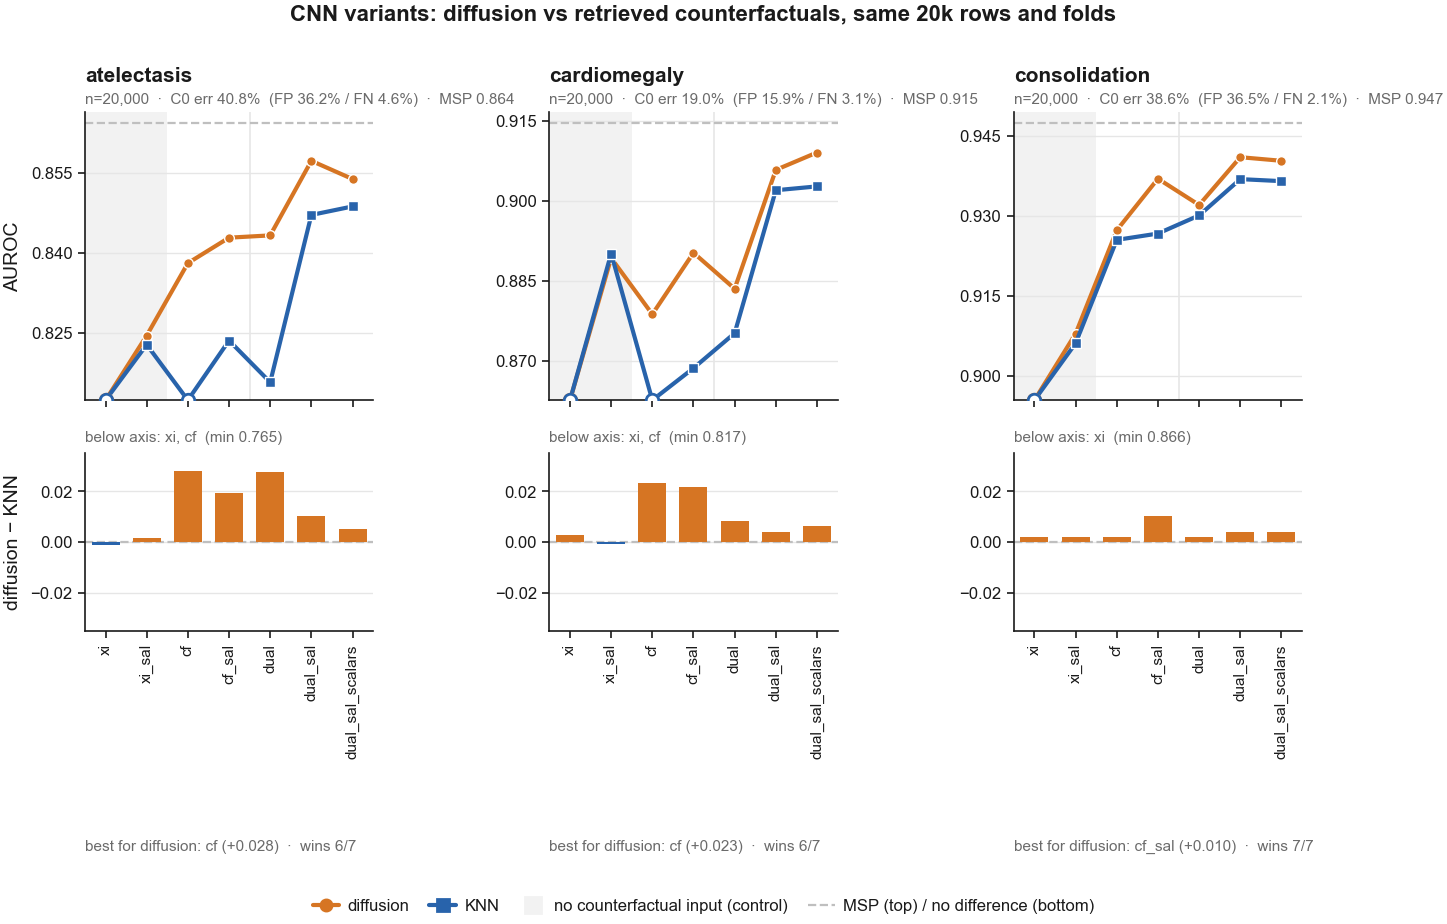

In [7]:
arm_compare(CNN_KEYS, kind="cnn", groups=CNN_GROUPS, shade=CNN_NO_CF,
            title="CNN variants: diffusion vs retrieved counterfactuals, "
                  "same 20k rows and folds");

## 1e. Trajectory models

Models that never look at the counterfactual image, nor at C0's probability on the query (**prob-free**,
no MSP skip): they only read **C0's probability along the diffusion trajectory** (recorded every 5
denoising steps, 30 values per level). Written by `c2_train_trajectory.py`; exploration in
`trajectory_fingerprint.ipynb`.

**x-axis: the MLP on blocks of the trajectory fingerprint** (32 hand-made features), each block alone,
then all together:

| block | features | what it describes |
|---|---|---|
| `LEVEL` | start / end value, net change, fitted level, threshold crossings | where the trajectory sits and whether it flips |
| `MONO` | monotone ratio, backtracking, reversals, rank correlation with time | how steadily it moves one way |
| `SHAPE` | slope, curvature, S-shape and misfit of a cubic fit | the shape of the curve |
| `DYN` | path length, velocity and acceleration summaries | how much and how fast it moves |

**Horizontal lines: sequence models on the whole trajectory** - a 1D CNN (feature map flattened, so it
knows *when* things happen) and a bidirectional GRU. Both read the logit of the probability of the class
the counterfactual is heading to, plus its step-to-step change.

Everything is trained the same way as the attribute MLP of `c2_block_ablation.ipynb`: class-balanced BCE
and early stopping on the AUC of a patient-grouped validation split. As in the attribute arm, each model is
trained on the `high` level only and applied per level; K averages the per-level scores.

**Plotted at K=1** (the `high`, most extreme counterfactual). K=3 is computed and saved too; set
`TRAJ_PLOT_K = [1, 3]` to draw it as a dashed MLP line (expected to be weaker: the models never
saw `mid`/`low` trajectories in training).

In [ ]:
TRAJ_BLOCKS  = ["LEVEL", "MONO", "SHAPE", "DYN", "ALL"]     # MLP configs, x-axis order
TRAJ_GROUPS  = [["LEVEL", "MONO", "SHAPE", "DYN"], ["ALL"]]  # hairline between single blocks and ALL
TRAJ_SEQ     = {"CNN": "1D CNN", "RNN": "bidirectional GRU"}  # horizontal lines
TRAJ_SEQ_LS  = {"CNN": "-.", "RNN": ":"}
TRAJ_PLOT_K  = [1]                                           # K=1: the high (extreme) CF only

def traj_dir(d, k=None, source=None):
    return os.path.join(C2, d, source or SOURCE, f"cf_{k or CF}", "trajectory")

def load_trajectory(disease, k=None, n_folds=5, source=None):
    """Pooled OOF predictions of c2_train_trajectory.py for one K, or None if not finished."""
    parts = []
    for i in range(n_folds):
        p = os.path.join(traj_dir(disease, k, source), f"fold_{i}_predictions.csv")
        if not os.path.exists(p):
            return None
        f = pd.read_csv(p); f["fold"] = i
        parts.append(f)
    return pd.concat(parts, ignore_index=True)


def traj_ladder(diseases=DISEASES, ks=None, win=0.05, ncols=3, panel=(FULL / 3, 76 * MM)):
    """MLP AUROC per fingerprint block (one line per K), CNN and RNN as horizontal lines."""
    ks, panels = ks or TRAJ_PLOT_K, []
    for d in diseases:
        frames = {k: f for k in ks if (f := load_trajectory(d, k)) is not None}
        if not frames:
            continue
        # MSP needs only C0's probability, which is in every frame and does not depend on K
        ref  = frames[next(iter(frames))]
        base = per_fold_auc(ref, msp(ref, d))
        mlp  = {k: {b: per_fold_auc(f, f"MLP_{b}_prob") for b in TRAJ_BLOCKS if f"MLP_{b}_prob" in f}
                for k, f in frames.items()}
        seq  = {k: {m: per_fold_auc(f, f"{m}_TRAJ_prob") for m in TRAJ_SEQ if f"{m}_TRAJ_prob" in f}
                for k, f in frames.items()}
        panels.append((d, ref, base, mlp, seq))

    if not panels:
        print("no trajectory predictions yet - run jobs/c2_trajectory.sh"); return

    # one K plotted -> the full trajectory orange; several -> the light-to-dark K ramp.
    # The CNN / RNN lines share their K's colour and are told apart by dash style.
    colors = K_COLOR if len(ks) > 1 else {ks[0]: FAMILY["traj"]}
    fig, axes = _grid(len(panels), ncols, panel)
    for ax, (d, ref, base, mlp, seq) in zip(axes, panels):
        # the y window must also contain the horizontal lines
        ylim = auroc_ylim({**mlp, **{("seq", k): v for k, v in seq.items()}}, base, win)
        # K=1 solid, K=3 dashed
        line_panel(ax, TRAJ_BLOCKS, mlp, TRAJ_GROUPS, ylim, base=base, colors=colors)
        for line in ax.lines:
            if line.get_label() == "K=3":
                line.set_linestyle("--")
        for k, vals in seq.items():
            for m, v in vals.items():
                ax.axhline(v, color=colors[k], ls=TRAJ_SEQ_LS[m], lw=LW["line"] * 0.8, zorder=2)
        _panel_title(ax, d, ref, base)
        ax.set_ylabel("AUROC")

    drawn   = sorted({k for _, _, _, s, _ in panels for k in s})
    markers = k_markers(drawn)
    handles = []
    for k in drawn:
        h = line_handle(colors[k], f"MLP, K={k} ({K_LEVELS[k]})", markers[k])
        if k == 3:
            h.set_linestyle("--")
        handles.append(h)
    for k in drawn:
        for m, name in TRAJ_SEQ.items():
            handles.append(Line2D([], [], color=colors[k], ls=TRAJ_SEQ_LS[m], lw=LW["line"] * 0.8,
                                  label=f"{name}, K={k}"))
    handles.append(msp_handle("MSP baseline"))
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.02))
    fig.suptitle("Trajectory models (prob-free), diffusion CFs: mean AUROC over 5 folds", y=1.0)
    fig.tight_layout(rect=(0, 0.02, 1, 0.99))
    return fig

traj_ladder();

# Aim 2 - is it better than the baseline?

Aim 1 showed which inputs carry correctness signal. This section asks the question that
decides whether any of it is worth deploying: **does it beat MSP?**

One attribute model and one CNN per disease, against the baseline. No config is singled out by
name - the winner is whatever the numbers choose.

**The search is over (config, K) jointly**, by mean fold AUROC. K is part of the method, so
fixing it and then reporting the gap would report an arbitrarily handicapped version. Every
candidate is scored on the same rows and the same folds, so the search is fair, and the chosen
K is printed alongside the config in every label.

This section deliberately shows only the strongest case the method can make, because a method
that cannot beat the baseline at its best does not beat it. The full ladders are in Aim 1.

> **No significance testing here.** The KNN notebook draws a 95% paired-bootstrap interval and
> a Holm-adjusted star on every row. Those are absent in this notebook, so a gap of +0.002 and
> a gap of +0.02 are drawn the same way and neither is claimed to be real. Run
> `bootstrapping.ipynb` against this arm before any of these numbers is quoted as a result.

## 2a. Best model vs MSP

Each disease gets two lines drawn from MSP: one for the best attribute model, one for the best
CNN, each the winner of a joint search over config and K. Length is the gain, blue and green
clear MSP and orange falls short, and the scale is shared across diseases so the lengths are
comparable. The absolute MSP level and the winning K are in the row labels.

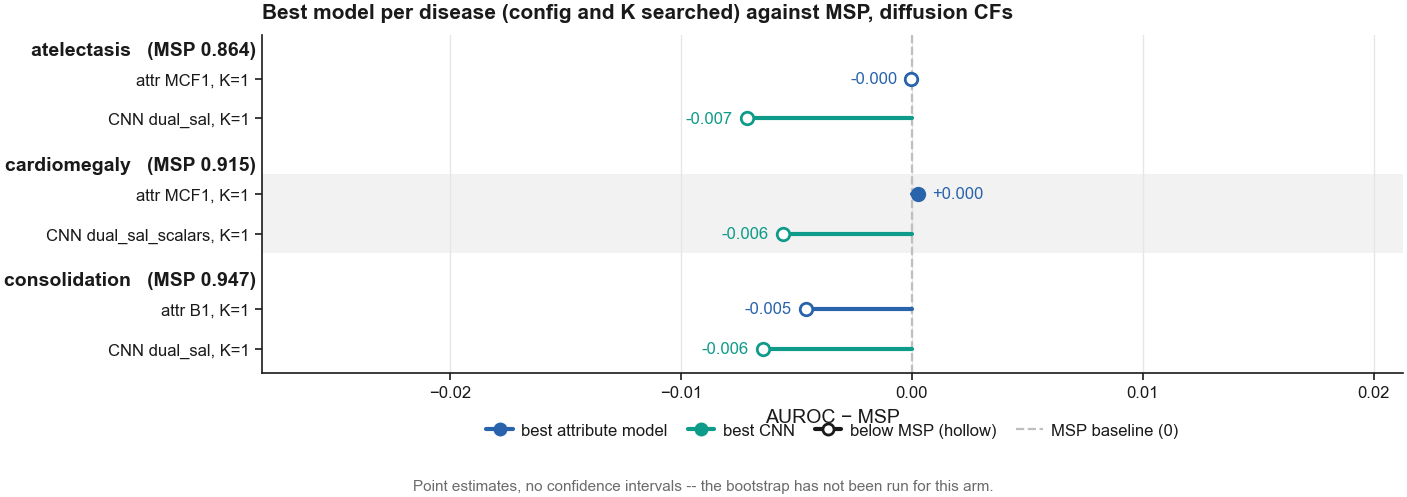

In [8]:
def best_attr(disease, model="MLP", ks=None):
    """Best (config, K) for the attribute models, by mean fold AUROC.

    Returns (config, K, score vector, frame, auroc). The score vector is returned rather
    than a column name because the winning K decides which frame the column lives in.
    """
    best = None
    for k in (ks or K_VALUES):
        df = load_attributes(disease, k)
        if df is None: continue
        for c, col in config_cols(df, model).items():
            a = per_fold_auc(df, col)
            if best is None or a > best[-1]:
                best = (c, k, df[col], df, a)
    return best


def best_cnn(disease, ks=None):
    """Best (variant, K) for the image models, by mean fold AUROC.
    Returns (variant, K, frame, column, auroc)."""
    best = None
    for k in (ks or K_VALUES):
        cnn = load_cnn(disease, k)
        if cnn is None: continue
        for key in CNN_KEYS:
            col = f"cnn_{key}"
            if col not in cnn.columns or not cnn[col].notna().all():
                continue
            a = per_fold_auc(cnn, col)
            if best is None or a > best[-1]:
                best = (key, k, cnn, col, a)
    return best


# "Below MSP" is drawn HOLLOW, not in a fourth hue: the palette validator could not
# place a fourth colour at adequate CVD separation from the three families, and sign is
# better carried by fill than by hue anyway.
BEST_LEGEND = [line_handle(BLUE, "best attribute model"),
               line_handle(TEAL, "best CNN"),
               Line2D([], [], color=INK, lw=LW["line"], marker="o", ms=4, mfc="white",
                      mew=1.0, label="below MSP (hollow)"),
               msp_handle("MSP baseline (0)")]


def best_vs_msp(diseases=DISEASES, model="MLP", ks=None, figsize=(FULL, 62 * MM),
                pad=0.006, gap=0.9):
    """One row per (disease, family): the AUROC gap of the best model over MSP.

    Deltas, not absolutes, because this is the comparison plot -- the length IS the answer
    to "is it better". The absolute MSP level is printed on each row label so nothing is lost.

    The CNN is scored on the rows it actually has, and MSP is recomputed on those same rows,
    so a CNN that finished on a subset is still compared like for like.

    Diseases are separated by a blank `gap` in y and named ONCE, in a heading above each
    pair: white space groups more strongly than a rule.

    Point estimates only -- see the note above. When the bootstrap is run for this arm, the
    whiskers and stars go back here.
    """
    blocks = []
    for d in diseases:
        ref = load_attributes(d, CF)
        if ref is None: continue
        rows = []

        a = best_attr(d, model, ks)
        if a:
            cfg, k, _score, adf, auc = a
            base = per_fold_auc(adf, msp(adf, d))
            rows.append((auc - base, BLUE, f"attr {cfg}, K={k}", base))

        c = best_cnn(d, ks)
        if c:
            key, k, cnn, col, _ = c
            m     = cnn.merge(ref[["path", f"{d}_prob"]], on="path", how="inner")
            cbase = per_fold_auc(m, msp(m, d))
            rows.append((per_fold_auc(m, col) - cbase, TEAL, f"CNN {key}, K={k}", cbase))

        if rows:
            blocks.append((d, rows))

    if not blocks:
        print("nothing to compare yet for", SOURCE); return

    # Lay the rows out with a gap between diseases, so y is no longer a plain range.
    placed, y = [], 0.0
    for d, rows in blocks:
        placed.append((d, y, [(y + j, *r) for j, r in enumerate(rows)]))
        y += len(rows) - 1 + gap + 1

    flat = [r for _, _, rs in placed for r in rs]
    # Room on each side for the printed value, which sits outside the dot; without it a
    # negative row's label runs off the left edge.
    ends   = [r[1] for r in flat] + [0.0]
    lo, hi = min(ends) - pad * 3.5, max(ends) + pad * 3.5

    fig, ax = plt.subplots(figsize=figsize)
    ax.axvline(0.0, color=GREY, ls="--", lw=LW["ref"], zorder=1)

    # Shade alternate disease blocks. A band reads as "these rows belong together".
    for i, (d, y0, rs) in enumerate(placed):
        if i % 2:
            ax.axhspan(y0 - 0.5, y0 + len(rs) - 0.5, color=SHADE, lw=0, zorder=0)

    for yy, v, colr, _, _base in flat:
        # Sign is carried by FILL, not hue: the family colour is kept so the row stays
        # identifiable as attributes or CNN, and a hollow dot says "below MSP".
        ax.plot([0.0, v], [yy, yy], color=colr, lw=LW["line"], zorder=2)
        ax.plot(v, yy, "o", ms=4.5, color=colr, zorder=4,
                mfc=colr if v >= 0 else "white", mec=colr, mew=1.0)
        ax.text(v + (0.0006 if v >= 0 else -0.0006), yy, f"{v:+.3f}",
                color=colr, fontsize=FS["small"], va="center",
                ha="left" if v >= 0 else "right")

    # The disease name sits above its pair, in the axes' left margin, so the tick labels
    # carry only what differs between the two rows.
    for d, y0, rs in placed:
        ax.text(-0.005, y0 - 0.72, f"{d}   (MSP {rs[0][4]:.3f})",
                transform=ax.get_yaxis_transform(), ha="right", va="center",
                fontsize=FS["base"], color=INK, fontweight="bold")

    ax.set_xlim(lo, hi)
    ax.set_yticks([r[0] for r in flat])
    ax.set_yticklabels([r[3] for r in flat], fontsize=FS["small"])
    ax.set_ylim(max(r[0] for r in flat) + 0.6, -1.1)
    ax.set_xlabel("AUROC − MSP")
    ax.grid(axis="x", zorder=0); ax.set_axisbelow(True)
    ax.legend(handles=BEST_LEGEND, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4)
    ax.set_title("Best model per disease (config and K searched) against MSP, diffusion CFs",
                 pad=6)
    fig.tight_layout()
    fig.text(0.5, -0.04, "Point estimates, no confidence intervals -- the bootstrap has not "
             "been run for this arm.", ha="center", fontsize=FS["tiny"], color=MUTED)
    return fig

best_vs_msp();

## 2b. Ensembling attributes and CNNs

The two families read different things - one the counterfactual *attributes*, the other the
*images* - so the question 2a leaves open is whether they are complementary: does combining
them rank C0's errors better than either alone?

Computed by `c2_ensemble.py`, not here; this cell only reads its `ensemble_summary.csv`. That
script takes the best attribute model and the best CNN for a disease, each by cross-validated
AUC, and combines them three ways:

| Combiner | What it does |
|---|---|
| `mean` | Average of the two probabilities. Assumes they are comparably calibrated. |
| `rank` | Average of within-fold percentile ranks. Calibration-free, so it asks whether the two *order* cases differently. |
| `lr` | Logistic regression on the two probabilities, fitted leave-one-fold-out. |

**The dashed line is the better of the two inputs, not MSP.** If both components already clear
MSP, an ensemble that only beats the baseline has shown nothing; a bar has to clear the dashed
line to mean anything.

No significance brackets here - see the Aim 2 note.

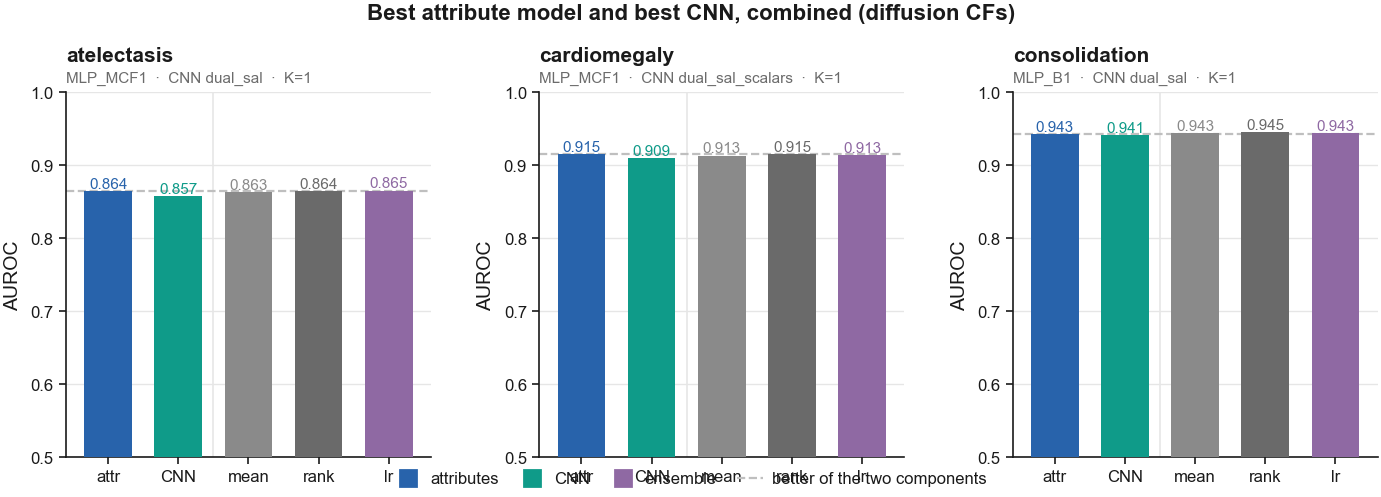

In [9]:
ENS_METHODS = ["mean", "rank", "lr"]
# The combiners are a MIX of families, so they take the neutral ensemble ink rather
# than borrowing a family hue -- which would claim they belong to one of the inputs.
# They are separated from each other by lightness, not colour.
ENS_COLOR   = {"mean": "#8A8A8A", "rank": "#6A6A6A", "lr": ENS}

# Fixed AUROC window, shared by every panel so heights compare across diseases.
Y_LO, Y_HI = 0.5, 1.0


def load_ensemble(disease, k, source=None):
    """`ensemble_summary.csv` for one disease and K, or None if that run is absent.
    Written by c2_ensemble.py; nothing is fitted here."""
    p = os.path.join(C2, disease, source or SOURCE, f"cf_{k}", "ensemble",
                     "ensemble_summary.csv")
    if not os.path.exists(p):
        return None
    df   = pd.read_csv(p)
    comp = df[df["kind"] == "component"].set_index("members")["auc_mean"]
    ens  = df[df["kind"] == "ensemble"].set_index("method")
    if comp.empty or ens.empty:
        return None
    # members is "<model>_prob"; only the attribute one carries an estimator prefix.
    attr = next((m for m in comp.index if m.split("_")[0] in ("MLP", "LR", "RF")), None)
    cnn  = next((m for m in comp.index if m != attr), None)
    if attr is None or cnn is None:
        return None
    return {"k": k, "attr": (attr[:-5], float(comp[attr])),
            "cnn": (cnn[:-5], float(comp[cnn])), "ens": ens}


def best_ensemble(disease, ks=None):
    """The K whose run has the strongest CNN -- K is searched, not pinned.

    Ranked by the CNN specifically, not by the better of the two: the attribute model
    usually wins, so ranking by the max would just pick the best attribute K and let the
    CNN follow. Chosen on what goes INTO the ensemble rather than on the ensemble's own
    score, since picking by the ensemble selects for a combiner getting lucky on one split.
    """
    cands = [e for k in (ks or K_VALUES) if (e := load_ensemble(disease, k))]
    return max(cands, key=lambda e: e["cnn"][1]) if cands else None


def ensemble_panel(ax, disease):
    """One disease: the two components and the three combiners, on an absolute axis.

    Absolute AUROC rather than a delta, because the question is where the ensembles sit
    RELATIVE TO THE BETTER COMPONENT -- which is a line on this axis, not a zero.
    """
    e = best_ensemble(disease)
    if e is None:
        ax.text(0.5, 0.5, f"{disease}\nno ensemble run", transform=ax.transAxes,
                ha="center", va="center", fontsize=FS["small"], color=MUTED)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_box_aspect(1)
        return

    (acfg, aauc), (ckey, cauc) = e["attr"], e["cnn"]
    names = ["attr", "CNN"] + ENS_METHODS
    vals  = [aauc, cauc] + [float(e["ens"].loc[m, "auc_mean"])
                            if m in e["ens"].index else np.nan for m in ENS_METHODS]
    # attributes blue, CNN teal -- the same hues they carry everywhere else.
    cols  = [BLUE, TEAL] + [ENS_COLOR[m] for m in ENS_METHODS]

    x = np.arange(len(names))
    msp_line(ax, max(aauc, cauc))
    for xi, v, c in zip(x, vals, cols):
        if np.isnan(v):
            continue
        ax.bar(xi, v, width=0.68, color=c, zorder=3)
        ax.text(xi, v, f"{v:.3f}", ha="center", va="bottom", fontsize=FS["tiny"],
                color=c, zorder=4)

    ax.set_ylim(Y_LO, Y_HI)
    ax.set_yticks(np.arange(Y_LO, Y_HI + 1e-9, 0.1))
    ax.axvline(1.5, color=HAIR, lw=LW["axis"], zorder=0)      # components | ensembles
    ax.set_xticks(x); ax.set_xticklabels(names, fontsize=FS["small"])
    ax.set_xlim(-0.6, len(names) - 0.4)
    ax.set_ylabel("AUROC")
    ax.set_title(disease, pad=11)
    ax.text(0.0, 1.02, f"{acfg}  ·  CNN {ckey}  ·  K={e['k']}", transform=ax.transAxes,
            ha="left", va="bottom", fontsize=FS["tiny"], color=MUTED)
    ax.grid(axis="y", zorder=0); ax.set_axisbelow(True)
    ax.set_box_aspect(1)


fig, axes = _grid(len(DISEASES), 3, panel=(FULL / 3, 62 * MM))
for ax, d in zip(axes, DISEASES):
    ensemble_panel(ax, d)
fig.legend(handles=[patch_handle(BLUE, "attributes"), patch_handle(TEAL, "CNN"),
                    patch_handle(ENS, "ensemble"),
                    msp_handle("better of the two components")],
           loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Best attribute model and best CNN, combined (diffusion CFs)", y=1.0)
fig.tight_layout(rect=(0, 0.02, 1, 0.99))

## 2c. Summary table

The numbers behind the figures, one row per disease. `Δ MSP` is the gap the lollipops draw.

In [10]:
def summary(diseases=DISEASES, model="MLP", ks=None):
    rows = []
    for d in diseases:
        ref = load_attributes(d, CF)
        if ref is None:
            continue
        r = {"disease": d, "n": len(ref)}
        r["MSP"] = per_fold_auc(ref, msp(ref, d))

        a = best_attr(d, model, ks)
        if a:
            cfg, k, _s, adf, auc = a
            r["attr"], r["attr K"], r["attr AUROC"] = cfg, k, auc
            r["attr Δ MSP"] = auc - per_fold_auc(adf, msp(adf, d))

        c = best_cnn(d, ks)
        if c:
            key, k, cnn, col, _ = c
            m = cnn.merge(ref[["path", f"{d}_prob"]], on="path", how="inner")
            r["CNN"], r["CNN K"] = key, k
            r["CNN AUROC"] = per_fold_auc(m, col)
            r["CNN Δ MSP"] = r["CNN AUROC"] - per_fold_auc(m, msp(m, d))

        e = best_ensemble(d, ks)
        if e is not None:
            best_comp = max(e["attr"][1], e["cnn"][1])
            for meth in ENS_METHODS:
                if meth in e["ens"].index:
                    r[f"ens {meth} Δ comp"] = float(e["ens"].loc[meth, "auc_mean"]) - best_comp
        rows.append(r)
    return pd.DataFrame(rows).round(4)

summary()

,disease,n,MSP,attr,attr K,attr AUROC,attr Δ MSP,CNN,CNN K,CNN AUROC,CNN Δ MSP,ens mean Δ comp,ens rank Δ comp,ens lr Δ comp
0,atelectasis,20000,0.8644,MCF1,1,0.8644,-0.0000,dual_sal,1,0.8573,-0.0071,-0.0011,-0.0006,0.0004
1,cardiomegaly,20000,0.9146,MCF1,1,0.9149,0.0003,dual_sal_scalars,1,0.9090,-0.0056,-0.0019,-0.0002,-0.0015
2,consolidation,20000,0.9474,B1,1,0.9428,-0.0046,dual_sal,1,0.9410,-0.0065,0.0005,0.0019,0.0005
